<a href="https://colab.research.google.com/github/illya52/pattern-recognition-practice/blob/main/PRO2_%D0%A5%D0%B8%D0%BC%D0%B8%D0%BD%D0%B5%D1%86%D1%8C_%D0%86%D0%BB%D0%BB%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris

from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/pattern-recognition-practice')
DATA_DIR = BASE_DIR / 'data'
PROCESSED_DIR = BASE_DIR / 'processed'
REPORTS_DIR = BASE_DIR / 'reports'

for d in [DATA_DIR, PROCESSED_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Налаштування готові! DATA_DIR =", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Налаштування готові! DATA_DIR = /content/drive/MyDrive/pattern-recognition-practice/data


In [10]:
iris_path = DATA_DIR / 'iris.csv'

if iris_path.exists():
    df = pd.read_csv(iris_path)
    print(f"Завантажено існуючий файл: {iris_path}")
else:
    print("Файл iris.csv не знайдено. Створюємо з sklearn...")
    iris = load_iris()
    df = pd.DataFrame(iris.data, columns=iris.feature_names)
    df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
    df.to_csv(iris_path, index=False)
    print(f"Створено та збережено: {iris_path}")

display(df.head())
print("Розмірність:", df.shape)

Завантажено існуючий файл: /content/drive/MyDrive/pattern-recognition-practice/data/iris.csv


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Розмірність: (150, 5)


In [11]:
import numpy as np
import pandas as pd

np.random.seed(42)

df_dirty = df.copy()

for col in df_dirty.columns[:4]:
    idx = np.random.choice(df_dirty.index, size=10, replace=False)
    df_dirty.loc[idx, col] = np.nan

idx_target = np.random.choice(df_dirty.index, size=5, replace=False)
df_dirty.loc[idx_target, 'species'] = np.nan

duplicates = df_dirty.sample(n=8, random_state=42)
df_dirty = pd.concat([df_dirty, duplicates], ignore_index=True)

text_values = ['unknown', '6.3 cm', 'помилка', 'N/A']
for val in text_values:
    idx = np.random.choice(df_dirty.index, size=2, replace=False)
    df_dirty.loc[idx, 'sepal length (cm)'] = val

idx_neg = np.random.choice(df_dirty.index, size=5, replace=False)
df_dirty.loc[idx_neg, 'petal width (cm)'] = -1.0
idx_zero = np.random.choice(df_dirty.index, size=5, replace=False)
df_dirty.loc[idx_zero, 'sepal width (cm)'] = 0.0

idx_extreme = np.random.choice(df_dirty.index, size=3, replace=False)
df_dirty.loc[idx_extreme, 'petal length (cm)'] = 100.0

device_variants = ['device_a', 'Device_A', 'device a', ' device_b ', 'DEVICE_B', 'device_c', 'Device_C']
df_dirty['measurement_device'] = np.random.choice(device_variants, size=len(df_dirty))

dirty_path = DATA_DIR / 'iris_dirty.csv'
df_dirty.to_csv(dirty_path, index=False)

print(f"Пошкоджений набір збережено за шляхом: {dirty_path}")
print("Розмірність нового набору:", df_dirty.shape)
display(df_dirty.head(10))

Пошкоджений набір збережено за шляхом: /content/drive/MyDrive/pattern-recognition-practice/data/iris_dirty.csv
Розмірність нового набору: (158, 10)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,sepal length (cm),petal width (cm),sepal width (cm),petal length (cm),measurement_device
0,5.1,3.5,1.4,0.2,setosa,NaN,NaN,NaN,NaN,Device_A
1,4.9,3.0,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device a
2,4.7,3.2,1.3,0.2,setosa,NaN,NaN,NaN,NaN,Device_C
3,4.6,3.1,1.5,0.2,setosa,NaN,NaN,NaN,NaN,device_c
4,5.0,3.6,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_b
5,5.4,3.9,1.7,0.4,setosa,NaN,NaN,NaN,NaN,DEVICE_B
6,4.6,3.4,1.4,0.3,NaN,NaN,NaN,NaN,NaN,DEVICE_B
7,5.0,3.4,1.5,0.2,setosa,NaN,NaN,NaN,NaN,Device_C
8,4.4,2.9,1.4,0.2,setosa,NaN,NaN,NaN,NaN,DEVICE_B
9,4.9,NaN,1.5,0.1,setosa,NaN,NaN,NaN,NaN,Device_C


In [12]:
print("=== Інформація про DataFrame ===")
df_dirty.info()

print("\n=== Пропущені значення (кількість) ===")
print(df_dirty.isna().sum())

print("\n=== Частка пропущених значень (%) ===")
print((df_dirty.isna().mean() * 100).round(2))

=== Інформація про DataFrame ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     140 non-null    float64
 1   sepal_width_cm      148 non-null    float64
 2   petal_length_cm     147 non-null    float64
 3   petal_width_cm      147 non-null    float64
 4   species             153 non-null    object 
 5   sepal length (cm)   8 non-null      object 
 6   petal width (cm)    5 non-null      float64
 7   sepal width (cm)    5 non-null      float64
 8   petal length (cm)   3 non-null      float64
 9   measurement_device  158 non-null    object 
dtypes: float64(7), object(3)
memory usage: 12.5+ KB

=== Пропущені значення (кількість) ===
sepal_length_cm        18
sepal_width_cm         10
petal_length_cm        11
petal_width_cm         11
species                 5
sepal length (cm)     150
petal width (cm)      153

In [13]:
print("Кількість повних дублікатів:", df_dirty.duplicated().sum())

Кількість повних дублікатів: 2


In [14]:
print(df_dirty.dtypes)

sepal_length_cm       float64
sepal_width_cm        float64
petal_length_cm       float64
petal_width_cm        float64
species                object
sepal length (cm)      object
petal width (cm)      float64
sepal width (cm)      float64
petal length (cm)     float64
measurement_device     object
dtype: object


In [15]:
col = 'sepal length (cm)'
converted = pd.to_numeric(df_dirty[col], errors='coerce')
mask = df_dirty[col].notna() & converted.isna()

print(f"Некоректні значення у стовпці '{col}':")
display(df_dirty.loc[mask, [col]])

Некоректні значення у стовпці 'sepal length (cm)':


,sepal length (cm)
10,unknown
15,6.3 cm
27,6.3 cm
74,помилка
112,unknown
137,N/A
150,N/A
154,помилка


In [16]:
def standardize_device(val):
    if pd.isna(val):
        return val
    return str(val).strip().lower().replace(' ', '_')

df_dirty['measurement_device'] = df_dirty['measurement_device'].apply(standardize_device)

print("Унікальні назви після виправлення:", df_dirty['measurement_device'].unique())

Унікальні назви після виправлення: ['device_a' 'device_c' 'device_b']


In [17]:
numeric_cols = df_dirty.columns[:4]

print("=== Фізично неможливі значення (<=0) ===")
for col in numeric_cols:
    mask = df_dirty[col] <= 0
    if mask.any():
        print(f"{col}: {mask.sum()} значень")

print("\n=== Аномалії за методом IQR (k=3) ===")
for col in numeric_cols:
    series = pd.to_numeric(df_dirty[col], errors='coerce')
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 3 * IQR, Q3 + 3 * IQR
    anomalies = df_dirty[(series < lower) | (series > upper)]
    if not anomalies.empty:
        print(f"{col}: знайдено {len(anomalies)} аномалій")

=== Фізично неможливі значення (<=0) ===

=== Аномалії за методом IQR (k=3) ===


In [18]:
df_clean = df_dirty.copy()

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

df_clean = df_clean.dropna(subset=['species']).reset_index(drop=True)

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    df_clean.loc[df_clean[col] <= 0, col] = np.nan
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 3 * IQR, Q3 + 3 * IQR
    df_clean.loc[(df_clean[col] < lower) | (df_clean[col] > upper), col] = np.nan

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

mode_val = df_clean['measurement_device'].mode()[0]
df_clean['measurement_device'] = df_clean['measurement_device'].fillna(mode_val)

print("Очищення завершено! Розмірність:", df_clean.shape)
display(df_clean.head())

Очищення завершено! Розмірність: (150, 10)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,sepal length (cm),petal width (cm),sepal width (cm),petal length (cm),measurement_device
0,5.1,3.5,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_a
1,4.9,3.0,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_a
2,4.7,3.2,1.3,0.2,setosa,NaN,NaN,NaN,NaN,device_c
3,4.6,3.1,1.5,0.2,setosa,NaN,NaN,NaN,NaN,device_c
4,5.0,3.6,1.4,0.2,setosa,NaN,NaN,NaN,NaN,device_b


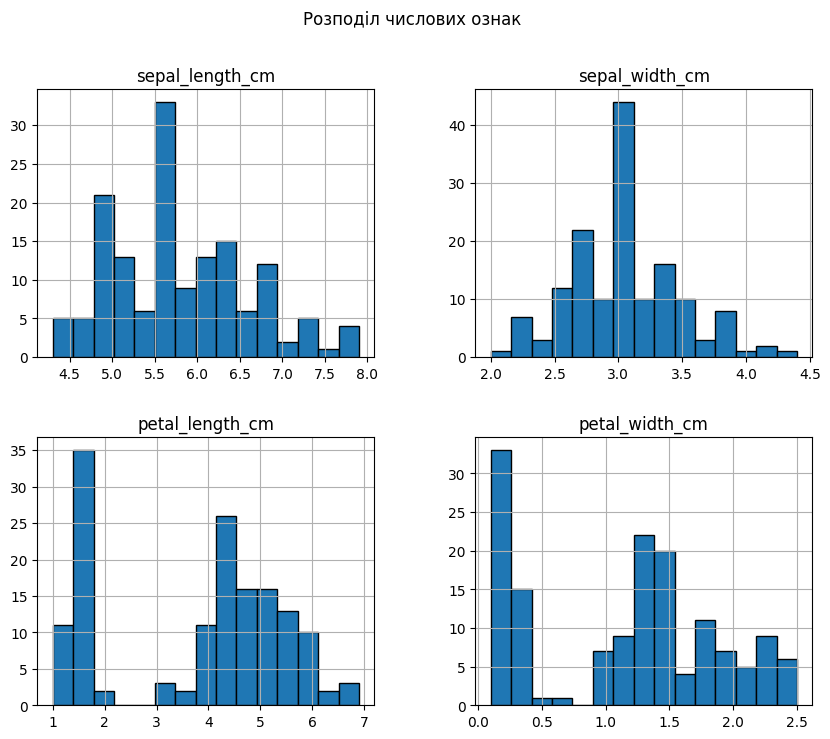

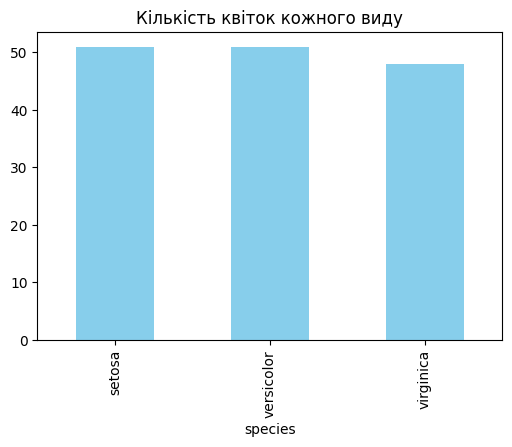

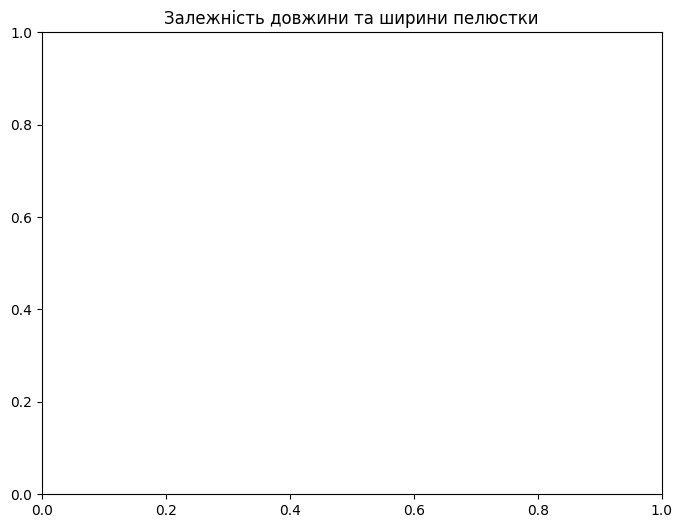

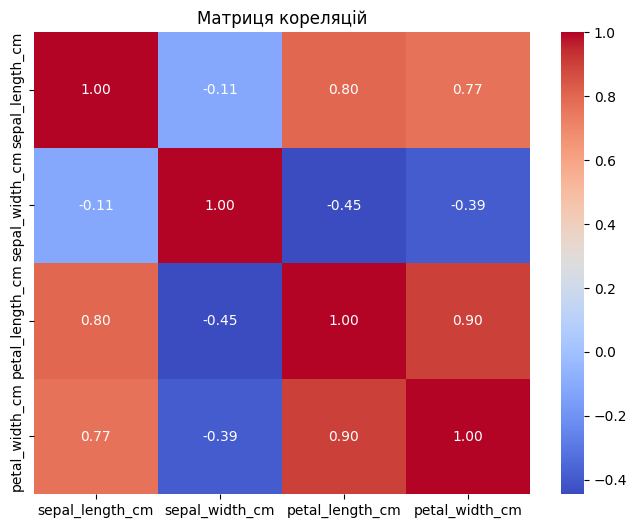

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

df_clean[numeric_cols].hist(figsize=(10, 8), bins=15, edgecolor='black')
plt.suptitle("Розподіл числових ознак")
plt.show()

plt.figure(figsize=(6, 4))
df_clean['species'].value_counts().plot(kind='bar', color='skyblue')
plt.title("Кількість квіток кожного виду")
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x='petal length (cm)', y='petal width (cm)', hue='species')
plt.title("Залежність довжини та ширини пелюстки")
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Матриця кореляцій")
plt.show()

In [21]:
df_encoded = pd.get_dummies(df_clean, columns=['measurement_device'], prefix='dev')

class_mapping = {name: i for i, name in enumerate(sorted(df_clean['species'].unique()))}
df_encoded['species_encoded'] = df_encoded['species'].map(class_mapping)
print("Кодування класів:", class_mapping)

feature_cols = [c for c in df_encoded.columns if c not in ['species', 'species_encoded']]
X = df_encoded[feature_cols]
y = df_encoded['species_encoded']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nЧастки класів у Train (навчання):")
print(y_train.value_counts(normalize=True).round(2))
print("\nЧастки класів у Test (тест):")
print(y_test.value_counts(normalize=True).round(2))

Кодування класів: {'setosa': 0, 'versicolor': 1, 'virginica': 2}

Частки класів у Train (навчання):
species_encoded
0    0.34
1    0.34
2    0.32
Name: proportion, dtype: float64

Частки класів у Test (тест):
species_encoded
1    0.33
2    0.33
0    0.33
Name: proportion, dtype: float64


In [22]:
import json

X_train.to_csv(PROCESSED_DIR / 'X_train.csv', index=False)
X_test.to_csv(PROCESSED_DIR / 'X_test.csv', index=False)
y_train.to_csv(PROCESSED_DIR / 'y_train.csv', index=False)
y_test.to_csv(PROCESSED_DIR / 'y_test.csv', index=False)
df_clean.to_csv(PROCESSED_DIR / 'iris_cleaned.csv', index=False)

with open(REPORTS_DIR / 'class_mapping.json', 'w') as f:
    json.dump(class_mapping, f)

summary_data = [
    {'step': 'Сира таблиця', 'rows': 150},
    {'step': 'Після очищення', 'rows': len(df_clean)}
]
pd.DataFrame(summary_data).to_csv(REPORTS_DIR / 'preprocessing_summary.csv', index=False)

print("Усі файли успішно збережено на Google Drive!")

Усі файли успішно збережено на Google Drive!


In [23]:
readme_path = BASE_DIR / 'README.md'
with open(readme_path, 'a', encoding='utf-8') as f:
    f.write("\n\n## Практична робота 2\n- Створено очищений набір даних.\n- Зроблено кодування ознак.\n- Дані розбито на train/test (80/20).\n")
print("README.md оновлено!")

!cd /content/drive/MyDrive/pattern-recognition-practice && git add . && git commit -m "PR2: EDA, очищення даних, кодування та формування train/test" && git push origin main

README.md оновлено!
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
